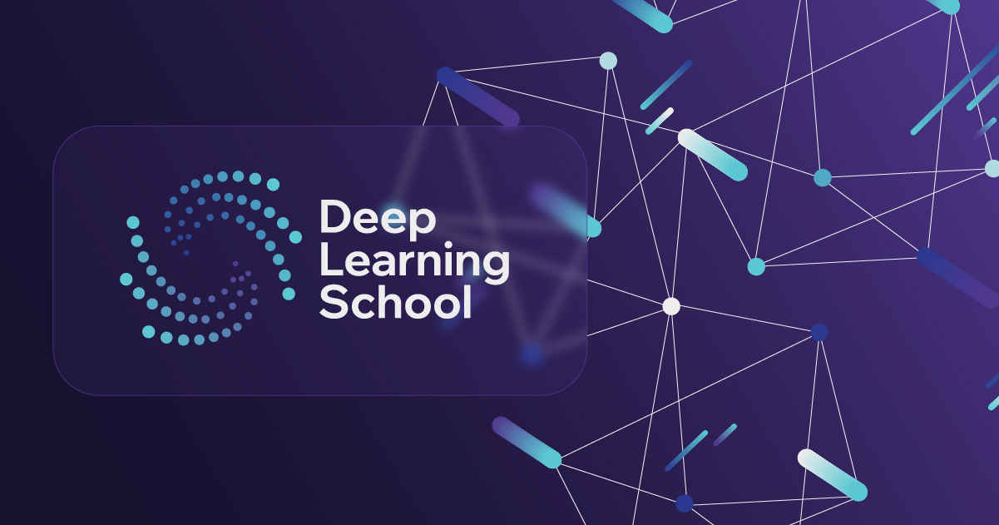

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание по теме "Механизм внимания.</b></h1>


Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

In [1]:
!pip install transformers

### Обработка датасета

In [2]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, AutoTokenizer, AutoModel, AutoConfig


import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from typing import Union, List
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

In [3]:
!gdown 13YIbphbWc62sfa-bCh8MLQWKizaXbQK9

Downloading...
From: https://drive.google.com/uc?id=13YIbphbWc62sfa-bCh8MLQWKizaXbQK9
To: /content/data_problems_translated.xlsx
100% 526k/526k [00:00<00:00, 35.7MB/s]


In [4]:
data = pd.read_excel('/content/data_problems_translated.xlsx', usecols='B:C')

In [5]:
data.head()

,problem_text,topic
0,To prove that the sum of the numbers of the ex...,number_theory
1,( b) Will the statement of the previous challe...,number_theory
2,The quadratic three-member graph with the coef...,polynoms
3,Can you draw on the surface of Rubik's cube a ...,combinatorics
4,"Dima, who came from Vrunlandia, said that ther...",graphs


Посмотрим на пропуски

In [6]:
data.isna().sum()

,0
problem_text,5
topic,0


In [7]:
data.shape

(5273, 2)

In [8]:
data[data.isna().any(axis=1)]

,problem_text,topic
1892,NaN,geometry
2052,NaN,polynoms
2724,NaN,number_theory
3473,NaN,geometry
4072,NaN,geometry


Так как данных с NaN достаточно мало, то их можно удалить

In [9]:
data.dropna(inplace=True)

In [10]:
data.shape

(5268, 2)

Закодируем темы целыми числами

In [11]:
data['topic'].unique()

array(['number_theory', 'polynoms', 'combinatorics', 'graphs', 'geometry',
       'invariant', 'dirichlet'], dtype=object)

In [12]:
encoder = LabelEncoder()
data_topic_encoded = encoder.fit_transform(data['topic'])

In [13]:
data_topic_encoded.shape

(5268,)

In [14]:
data['topic'] = data_topic_encoded

In [15]:
data.sample(10)

,problem_text,topic
1246,The number of n is called perfect if x(n) = 2n...,5
1605,The number x ends by 5. Prove that x2 ends by 25.,5
1488,On the larger side of the AC of the ABC triang...,2
2572,The city of Urupinsk has three lines and has a...,3
3748,"There were 100 doors, each with its own key (o...",1
4501,There are 99 natural numbers in the circle. It...,5
978,Prove that a link graph with 2n odd vertices c...,0
2325,Prove that a convex 13-gon can't be cut into p...,5
3219,"To prove that out of any 2001, there are two c...",1
2976,Is there such a natural number that the work o...,5


Разделим датасет на тренировочную часть и тестовую

In [16]:
X = data['problem_text'].values
y = data['topic'].values

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2, stratify=y)

Токенизуруем задачи

In [18]:
tokenizer_rubert = BertTokenizer.from_pretrained("cointegrated/rubert-tiny2")
tokenized_data_train_rubert = tokenizer_rubert(X_train.tolist(), padding=True, truncation=True, max_length=512, return_tensors='pt')
tokenized_data_test_rubert = tokenizer_rubert(X_test.tolist(), padding=True, truncation=True, max_length=512, return_tensors='pt')

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [19]:
tokenizer_mathbert = BertTokenizer.from_pretrained("tbs17/MathBert")
tokenized_data_train_mathbert = tokenizer_mathbert(X_train.tolist(), padding=True, truncation=True, max_length=512, return_tensors='pt')
tokenized_data_test_mathbert = tokenizer_mathbert(X_test.tolist(), padding=True, truncation=True, max_length=512, return_tensors='pt')

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Создадим Dataset и DataLoader

In [20]:
train_dataset_rubert = TensorDataset(tokenized_data_train_rubert.input_ids, tokenized_data_train_rubert.attention_mask, torch.from_numpy(y_train))
test_dataset_rubert = TensorDataset(tokenized_data_test_rubert.input_ids, tokenized_data_test_rubert.attention_mask, torch.from_numpy(y_test))

In [21]:
train_dataset_mathbert = TensorDataset(tokenized_data_train_mathbert.input_ids, tokenized_data_train_mathbert.attention_mask, torch.from_numpy(y_train))
test_dataset_mathbert= TensorDataset(tokenized_data_test_mathbert.input_ids, tokenized_data_test_mathbert.attention_mask, torch.from_numpy(y_test))

In [22]:
train_dataloader_rubert = DataLoader(train_dataset_rubert, batch_size=8, shuffle=True)
test_dataloader_rubert = DataLoader(test_dataset_rubert, batch_size=8, shuffle=False)

In [23]:
train_dataloader_mathbert= DataLoader(train_dataset_mathbert, batch_size=8, shuffle=True)
test_dataloader_mathbert = DataLoader(test_dataset_mathbert, batch_size=8, shuffle=False)

### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [24]:
### This is just an interface example. You may change it if you want.

class TransformerClassificationModel(nn.Module):
    def __init__(self, base_transformer_model: Union[str, nn.Module], num_classes: int):
        super().__init__()
        config  = AutoConfig.from_pretrained(base_transformer_model)
        config.output_attentions = True
        self.backbone = AutoModel.from_pretrained(base_transformer_model, config=config)
        hidden_size = self.backbone.config.hidden_size
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, inputs, attention_mask=None):
        x = self.backbone(inputs, attention_mask)
        x = x.last_hidden_state[:, 0, :]
        x = self.classifier(x)
        return x

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [25]:
def freeze_backbone_function(model: TransformerClassificationModel):
    for param in model.backbone.parameters():
        param.requires_grad = False
    return model

### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [26]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [34]:
import copy

def train_transformer(transformer_model, name, epoch, dataloaders, freeze_backbone=True):
    model = copy.deepcopy(transformer_model)
    # Оптимизатор будет настраиваться в зависимости от freeze_backbone:
    # если нет freeze, то для предобученной модели применим более маленький learning rate
    if freeze_backbone:
        model = freeze_backbone_function(model)
        optimizer = torch.optim.Adam(model.parameters())
    else:
        optimizer = torch.optim.Adam([
            {'params': model.backbone.parameters(), 'lr': 1e-5},
            {'params': model.classifier.parameters(), 'lr': 1e-3}
        ])
    criterion = nn.CrossEntropyLoss()
    model.to(device)
    best_val_loss = float('inf')
    for i in range(epoch):
        model.train()
        total_loss = 0.0
        for embeddings, attention_mask, labels in tqdm(dataloaders[0]):
            embeddings = embeddings.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            outp = model(embeddings, attention_mask)
            loss = criterion(outp, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        total_loss /= len(dataloaders[0])
        tqdm.write(f"Train epoch: {i + 1}, loss: {total_loss:.4f}")
        val_loss, val_acc = evaluate_transformer(model, dataloaders[1])
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f'best_model_{name}.pth')
            tqdm.write(f'Эпоха {i + 1}: модель сохранена с val_loss = {val_loss:.4f}, accuracy = {val_acc:.4f}')
        else:
            tqdm.write(f"Val epoch: {i + 1}, loss = {val_loss:.4f}, accuracy = {val_acc:.4f}")

    return model

In [28]:
def evaluate_transformer(model, dataloader):
    with torch.no_grad():
        criterion = nn.CrossEntropyLoss()
        model.to(device)
        model.eval()
        total_loss = 0.0
        total_correct = 0.0
        for embeddings, attention_mask, labels in tqdm(dataloader):
            embeddings = embeddings.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)
            outp = model(embeddings, attention_mask)

            loss = criterion(outp, labels)
            total_loss += loss.item()

            preds = outp.argmax(-1)
            total_correct += (preds == labels).sum().item()

        total_loss /= len(dataloader)
        total_correct /= len(dataloader.dataset)
    return total_loss, total_correct

### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [35]:
num_epoch = 10
num_classes = len(encoder.classes_)

In [36]:
rubert_tiny_transformer_model = TransformerClassificationModel("cointegrated/rubert-tiny2", num_classes)
rubert_tiny_finetuned_with_freezed_backbone = train_transformer(rubert_tiny_transformer_model, "rubert-tiny2_freeze", num_epoch, [train_dataloader_rubert, test_dataloader_rubert], freeze_backbone=True)

rubert_tiny_transformer_model = TransformerClassificationModel("cointegrated/rubert-tiny2", num_classes)
rubert_tiny_full_finetuned = train_transformer(rubert_tiny_transformer_model, "rubert-tiny2", num_epoch, [train_dataloader_rubert, test_dataloader_rubert], freeze_backbone=False)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/527 [00:00<?, ?it/s]

Train epoch: 1, loss: 1.2355


  0%|          | 0/132 [00:00<?, ?it/s]

...

Val epoch: 9, loss = 1.0120, accuracy = 0.5901


  0%|          | 0/527 [00:00<?, ?it/s]

Train epoch: 10, loss: 0.6970


  0%|          | 0/132 [00:00<?, ?it/s]

Val epoch: 10, loss = 1.0121, accuracy = 0.5835


In [37]:
state_dict = torch.load('best_model_rubert-tiny2_freeze.pth', weights_only=True)
best_rubert_freeze = TransformerClassificationModel("cointegrated/rubert-tiny2", num_classes)
best_rubert_freeze.load_state_dict(state_dict)
best_rubert_freeze_loss, best_rubert_freeze_accuracy = evaluate_transformer(best_rubert_freeze, test_dataloader_rubert)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/132 [00:00<?, ?it/s]

In [38]:
print(f'Лосс на валидации = {best_rubert_freeze_loss}, точность на валидации = {best_rubert_freeze_accuracy:.2f}')

Лосс на валидации = 0.9905530453631373, точность на валидации = 0.61


In [39]:
state_dict = torch.load('best_model_rubert-tiny2.pth', weights_only=True)
best_rubert_finetuned = TransformerClassificationModel("cointegrated/rubert-tiny2", num_classes)
best_rubert_finetuned.load_state_dict(state_dict)
best_rubert_finetuned_loss, best_rubert_finetuned_accuracy = evaluate_transformer(best_rubert_finetuned, test_dataloader_rubert)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/132 [00:00<?, ?it/s]

In [40]:
print(f'Лосс на валидации = {best_rubert_finetuned_loss}, точность на валидации = {best_rubert_finetuned_accuracy:.2f}')

Лосс на валидации = 0.9696793455743429, точность на валидации = 0.60


Лосс лучше на модели, а точность чуть выше у модели, которая тренировалась с заморозкой, которая тренировалась без заморозки, так как она дообучала не только классификатор, но и предобученную модель, но, зато, модель с заморозкой backbone обучалась в 3,5 раза быстрее

### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [43]:
math_bert_transformer_model = TransformerClassificationModel("tbs17/MathBert", num_classes)
math_bert_finetuned_with_freezed_backbone = train_transformer(math_bert_transformer_model, "MathBert_freeze", num_epoch, [train_dataloader_mathbert, test_dataloader_mathbert], freeze_backbone=True)

math_bert_transformer_model = TransformerClassificationModel("tbs17/MathBert", num_classes)
math_bert_full_finetuned = train_transformer(math_bert_transformer_model, "MathBert", num_epoch, [train_dataloader_mathbert, test_dataloader_mathbert], freeze_backbone=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/527 [00:00<?, ?it/s]

Train epoch: 1, loss: 1.3140


  0%|          | 0/132 [00:00<?, ?it/s]

...

Val epoch: 9, loss = 1.3372, accuracy = 0.5484


  0%|          | 0/527 [00:00<?, ?it/s]

Train epoch: 10, loss: 0.4227


  0%|          | 0/132 [00:00<?, ?it/s]

Val epoch: 10, loss = 1.4779, accuracy = 0.5939


In [44]:
state_dict = torch.load('best_model_MathBert_freeze.pth', weights_only=True)
best_mathbert_freeze = TransformerClassificationModel("tbs17/MathBert", num_classes)
best_mathbert_freeze.load_state_dict(state_dict)
best_mathbert_freeze_loss, best_mathbert_freeze_accuracy = evaluate_transformer(best_mathbert_freeze, test_dataloader_mathbert)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/132 [00:00<?, ?it/s]

In [55]:
print(f'Лосс на валидации = {best_mathbert_freeze_loss}, точность на валидации = {best_mathbert_freeze_accuracy:.2f}')

Лосс на валидации = 1.0891377810727467, точность на валидации = 0.57


In [46]:
state_dict = torch.load('best_model_MathBert.pth', weights_only=True)
best_mathbert_finetune = TransformerClassificationModel("tbs17/MathBert", num_classes)
best_mathbert_finetune.load_state_dict(state_dict)
best_mathbert_finetune_loss, best_mathbert_finetune_accuracy = evaluate_transformer(best_mathbert_finetune, test_dataloader_mathbert)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/132 [00:00<?, ?it/s]

In [56]:
print(f'Лосс на валидации = {best_mathbert_finetune_loss}, точность на валидации = {best_mathbert_finetune_accuracy:.2f}')

Лосс на валидации = 0.9723284124876513, точность на валидации = 0.62


У модели без заморозки получился меньший лосс и большая точность на валидации. Это возникает из-за того, что модель `tbs17/MathBert` была обучена на корпусе похожих данных - математических задач, а затем мы её дообучили на наших задачах.Модель стала лучше улавливать закономерности, чем модель, которая обучалась просто на обычных текстовых данных

### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [48]:
def draw_first_layer_attention_maps(attention_head_ids: List[int], text: str, model: TransformerClassificationModel, tokenizer):
    inputs = tokenizer(text, return_tensors="pt")
    input_ids = inputs["input_ids"].to(device)

    model.to(device)
    model.eval()
    with torch.no_grad():
        outputs = model.backbone(input_ids=input_ids, output_attentions=True)
        first_layer_attentions = outputs.attentions[0]

    num_heads = first_layer_attentions.size(1)
    if num_heads % 4 == 0:
        num_size = num_heads // 4
    else:
        num_size = num_heads // 4 + 1
    fig, axes = plt.subplots(4, num_size, figsize=(35, 30))
    for idx, head_id in enumerate(attention_head_ids):
        ax = axes.flat[idx]
        attention = first_layer_attentions[0, head_id].cpu().numpy()
        ax.matshow(attention, cmap='viridis')
        ax.set_title(f'Head {head_id}')
        ax.set_xlabel('Tokens')
        ax.set_ylabel('Tokens')
        ax.set_xticks(range(len(input_ids[0])))
        ax.set_xticklabels(tokenizer.convert_ids_to_tokens(input_ids[0]), rotation=90)
        ax.set_yticks(range(len(input_ids[0])))
        ax.set_yticklabels(tokenizer.convert_ids_to_tokens(input_ids[0]))
    plt.tight_layout()
    plt.show()

### Задание 7 (1 балл)

Проведите инференс для всех моделей **ДО ДООБУЧЕНИЯ** на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)

Delete in a row the numbers 1 to 9 (each time) so that every two consecutively protruding numbers would give a two-digit number divided by 7 or 13.


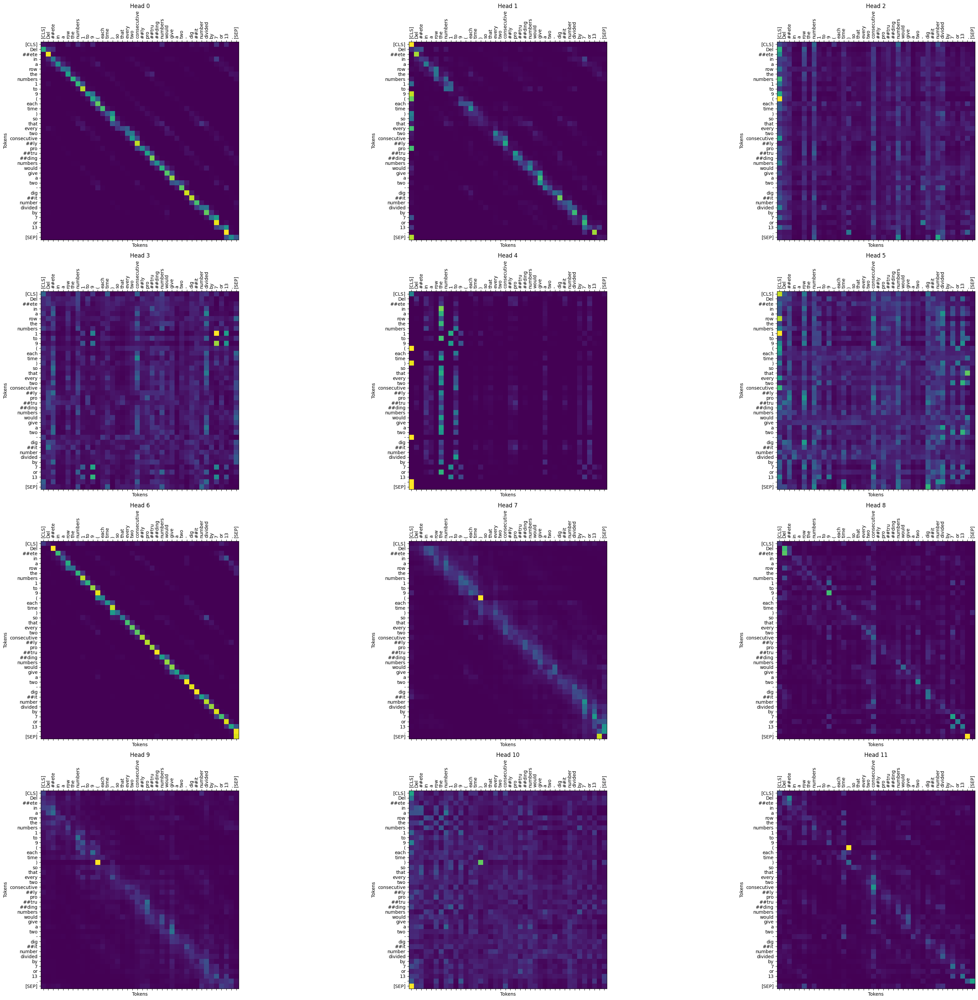

Find the smallest number, which only consists of zeros and units divided by 225.


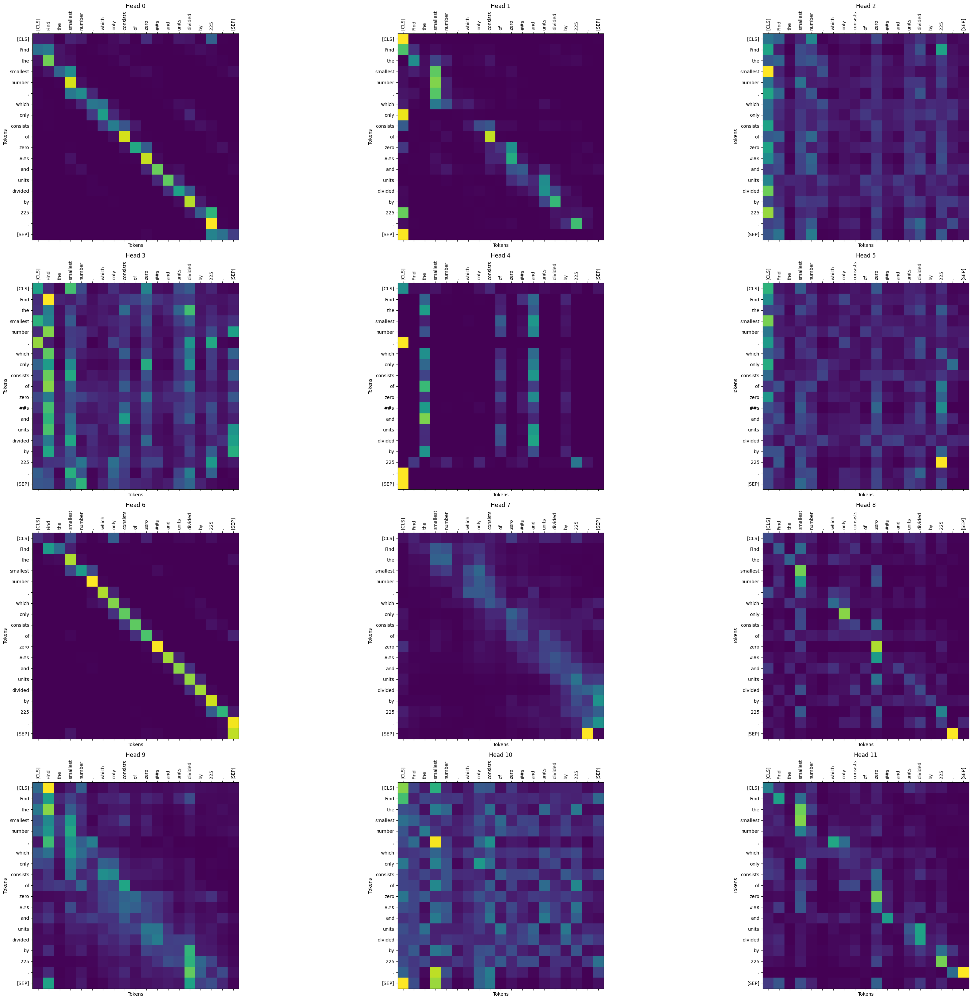

There are two numbers written on the board in the lab, and Pete's senior research officer wipes both numbers off the board every day and writes their average arithmetic and average harmonics instead. On the morning of the first day, the numbers 1 and 2 were written on the board. Find the work of the numbers recorded on the board on the evening of 1999.


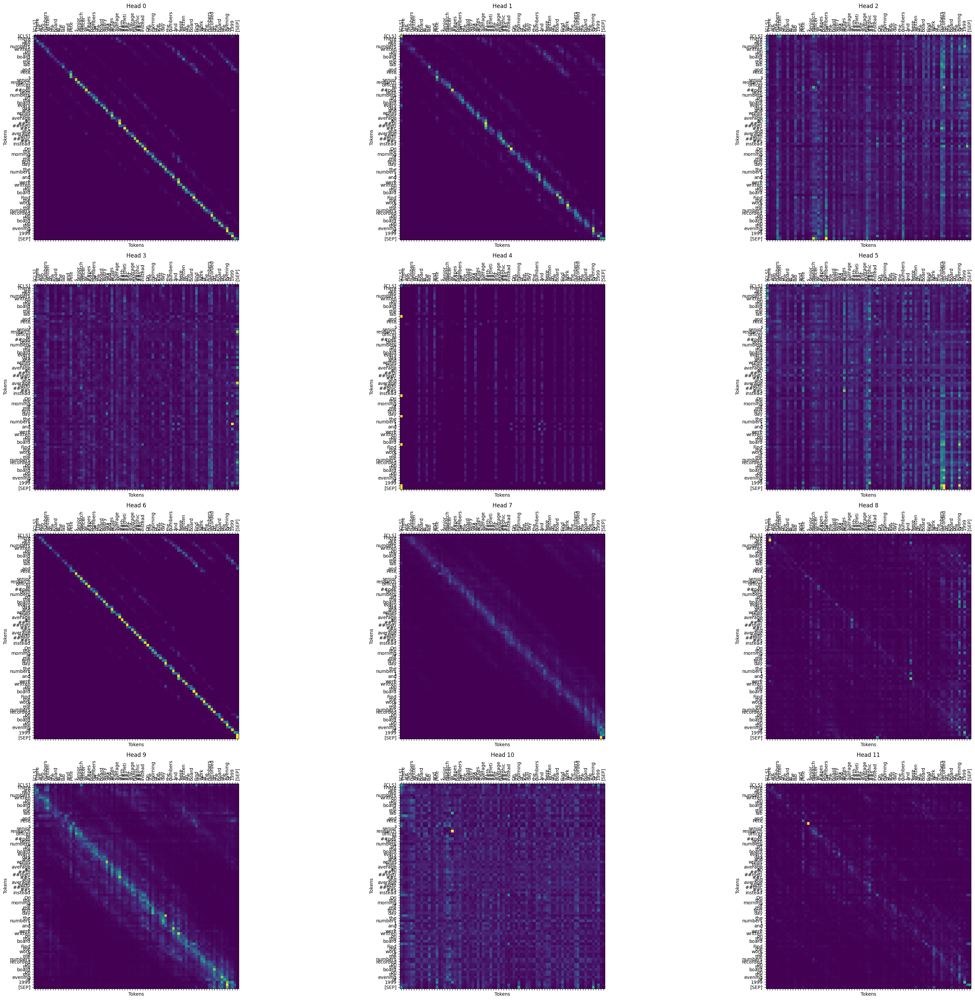

In [49]:
texts_to_analyze = X_test[:3].tolist()
for text in texts_to_analyze:
    print(text)
    draw_first_layer_attention_maps(list(range(rubert_tiny_transformer_model.backbone.config.num_attention_heads)), text, rubert_tiny_transformer_model, tokenizer_rubert)

Можно заметить, что есть головы, которые обращают внимание на следующее слово. Также есть головы, которые обращают внимание на грамматические конструкции, например, to + verb

Delete in a row the numbers 1 to 9 (each time) so that every two consecutively protruding numbers would give a two-digit number divided by 7 or 13.


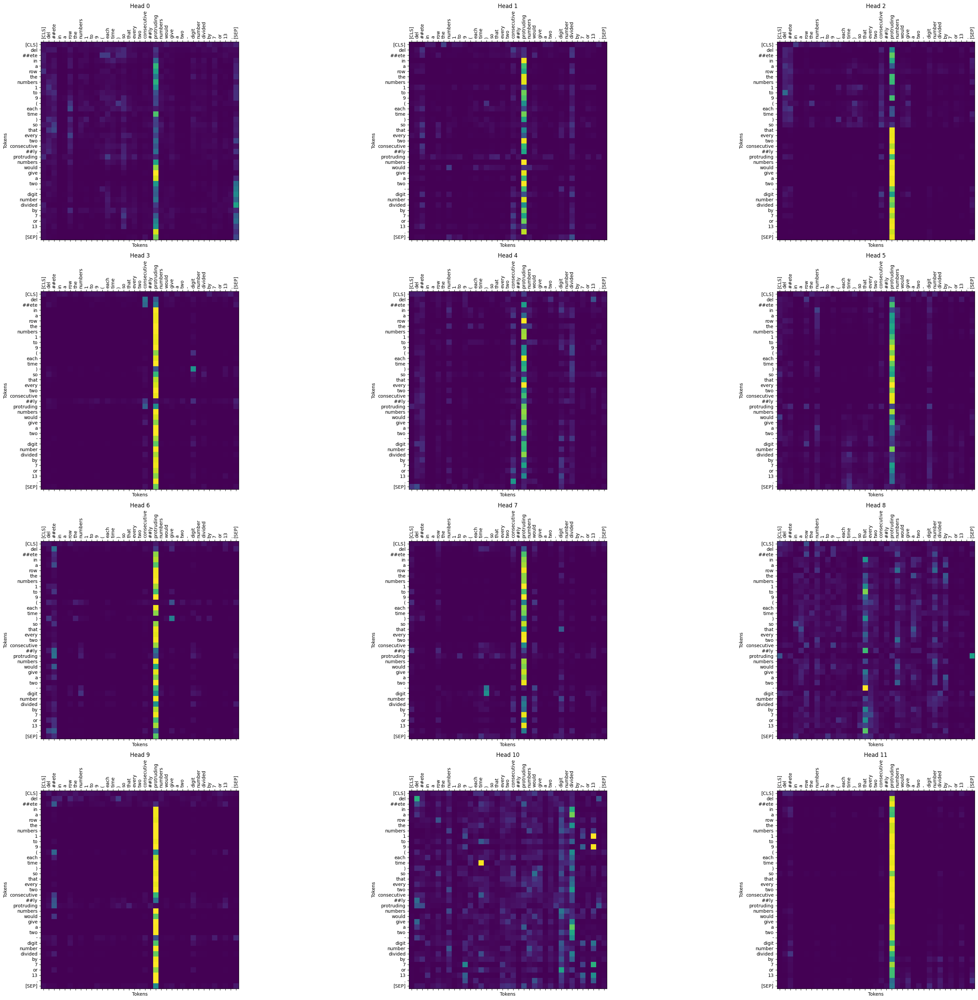

Find the smallest number, which only consists of zeros and units divided by 225.


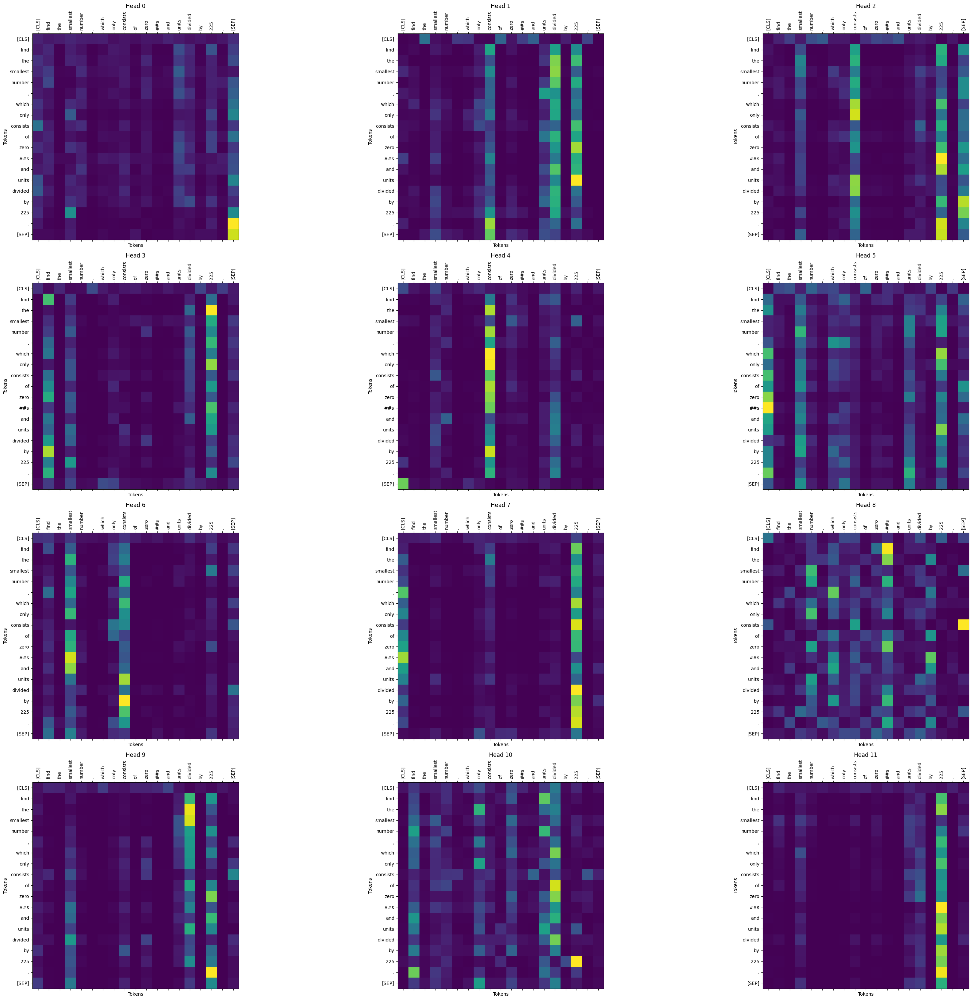

There are two numbers written on the board in the lab, and Pete's senior research officer wipes both numbers off the board every day and writes their average arithmetic and average harmonics instead. On the morning of the first day, the numbers 1 and 2 were written on the board. Find the work of the numbers recorded on the board on the evening of 1999.


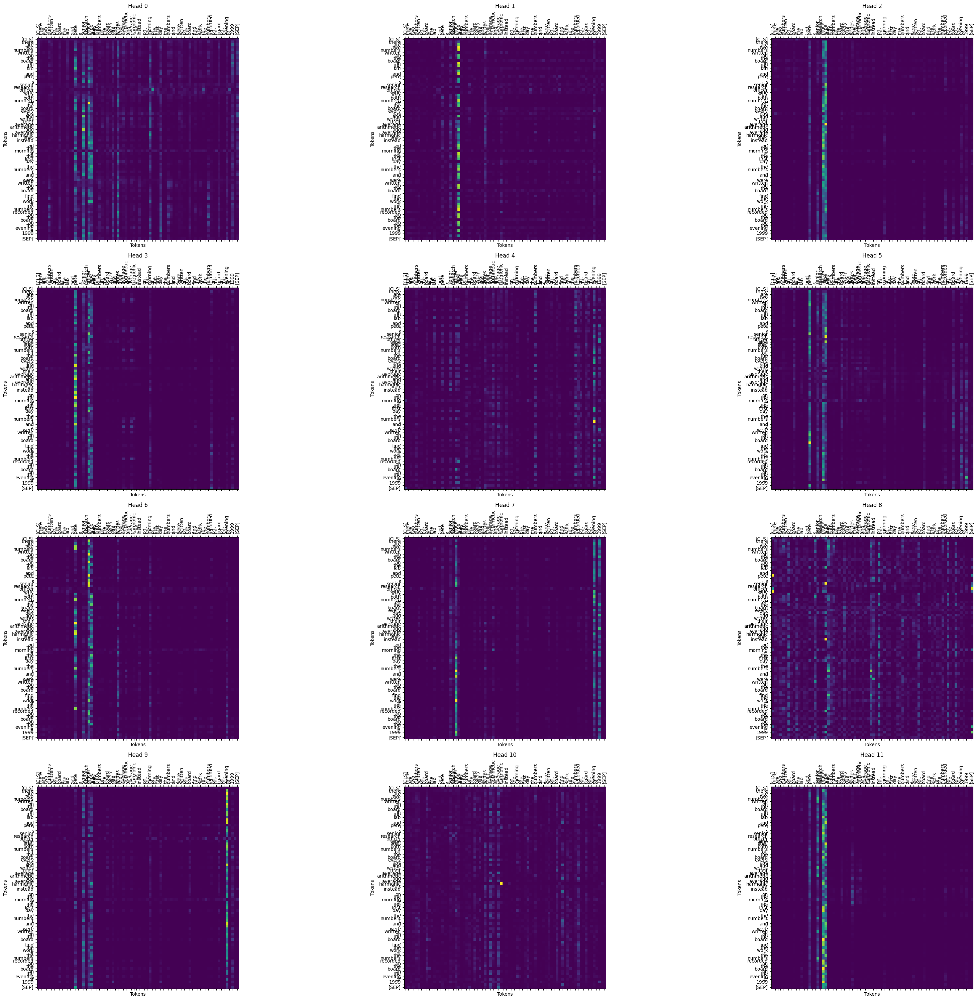

In [50]:
for text in texts_to_analyze:
    print(text)
    draw_first_layer_attention_maps(list(range(math_bert_transformer_model.backbone.config.num_attention_heads)), text, math_bert_transformer_model, tokenizer_mathbert)

Можно заметить, что головы реагируют на слова, свойственные математическим задачам - consists, divided

### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?

Delete in a row the numbers 1 to 9 (each time) so that every two consecutively protruding numbers would give a two-digit number divided by 7 or 13.


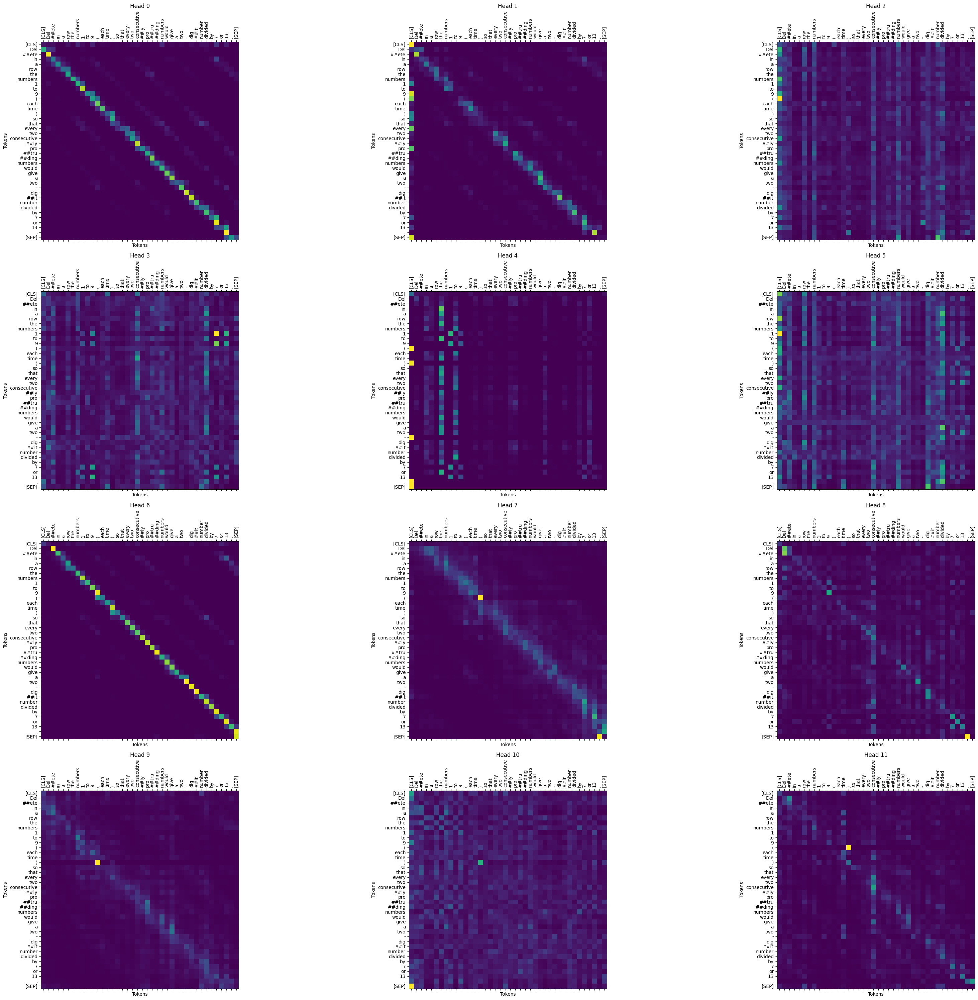

Find the smallest number, which only consists of zeros and units divided by 225.


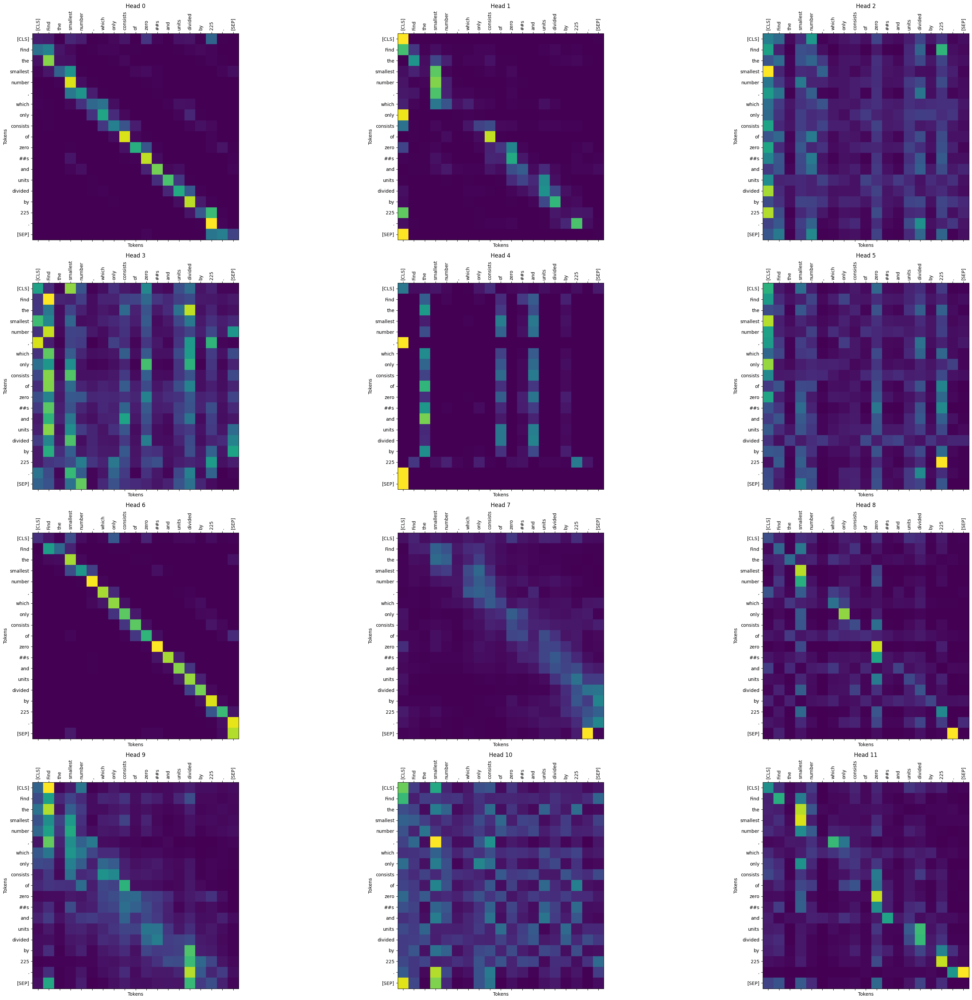

There are two numbers written on the board in the lab, and Pete's senior research officer wipes both numbers off the board every day and writes their average arithmetic and average harmonics instead. On the morning of the first day, the numbers 1 and 2 were written on the board. Find the work of the numbers recorded on the board on the evening of 1999.


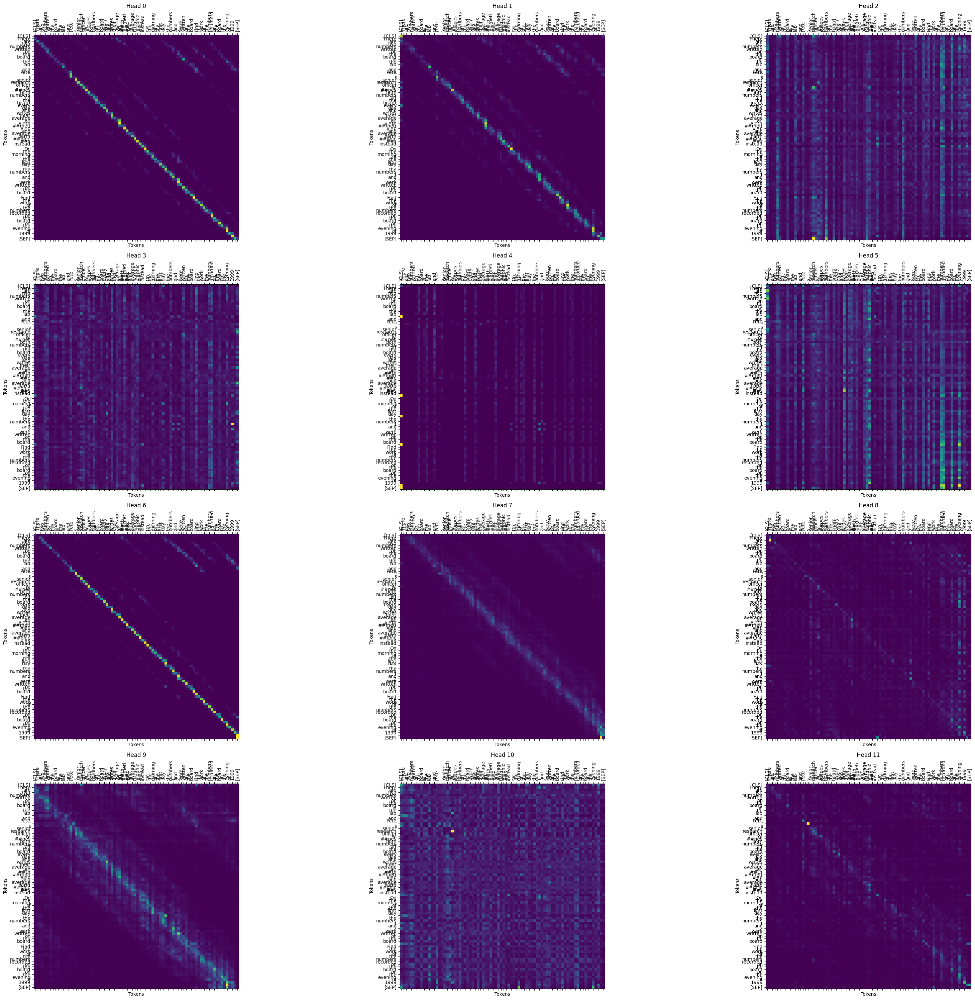

In [51]:
for text in texts_to_analyze:
    print(text)
    draw_first_layer_attention_maps(list(range(best_rubert_finetuned.backbone.config.num_attention_heads)), text, best_rubert_finetuned, tokenizer_rubert)

Для данной модели - обычная модель - тоже практически ничего не изменилось, модель также улавливает грамматические конструкции и обращает внимание на слова, характерные для математических задач

Delete in a row the numbers 1 to 9 (each time) so that every two consecutively protruding numbers would give a two-digit number divided by 7 or 13.


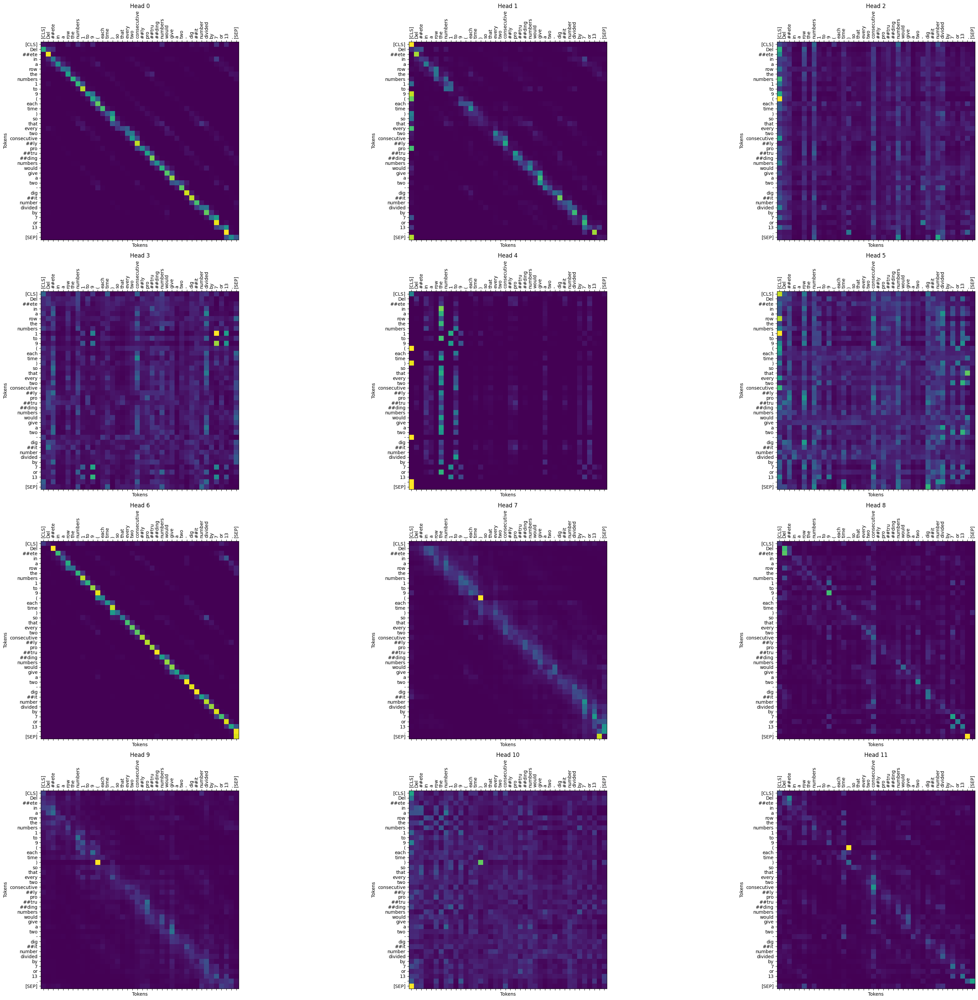

Find the smallest number, which only consists of zeros and units divided by 225.


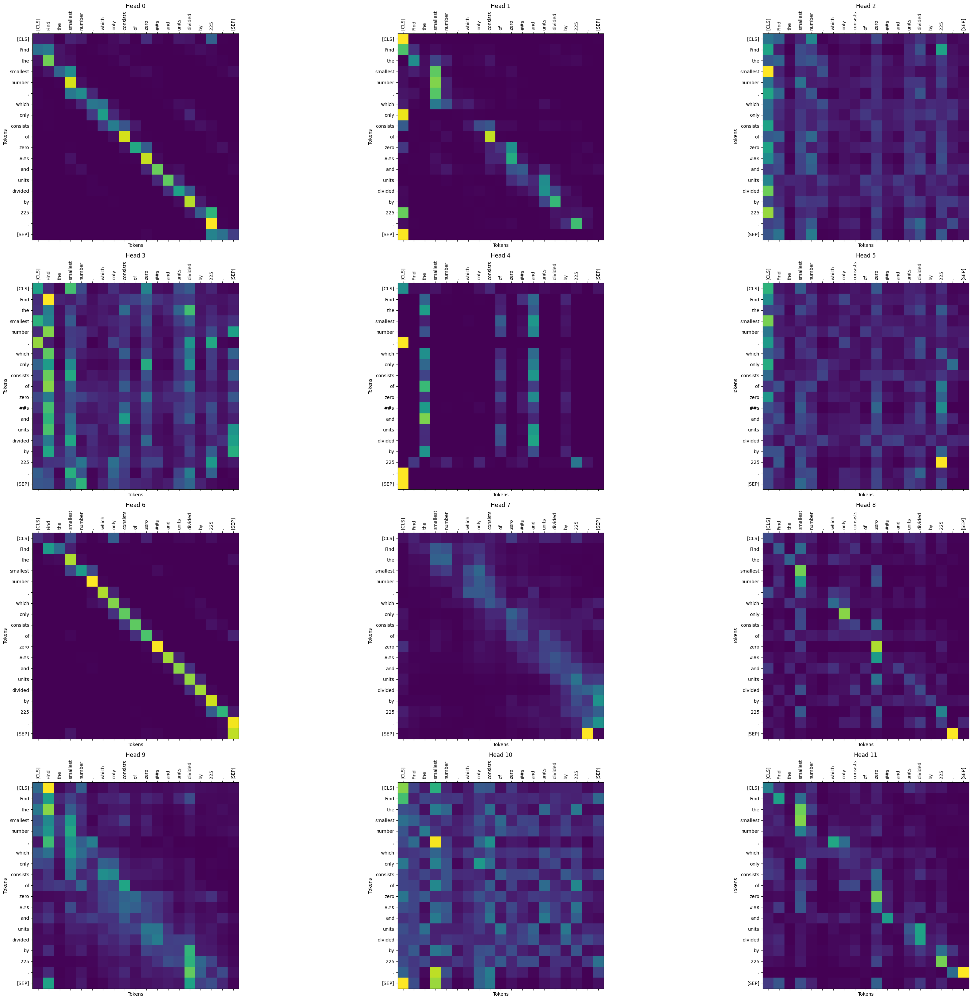

There are two numbers written on the board in the lab, and Pete's senior research officer wipes both numbers off the board every day and writes their average arithmetic and average harmonics instead. On the morning of the first day, the numbers 1 and 2 were written on the board. Find the work of the numbers recorded on the board on the evening of 1999.


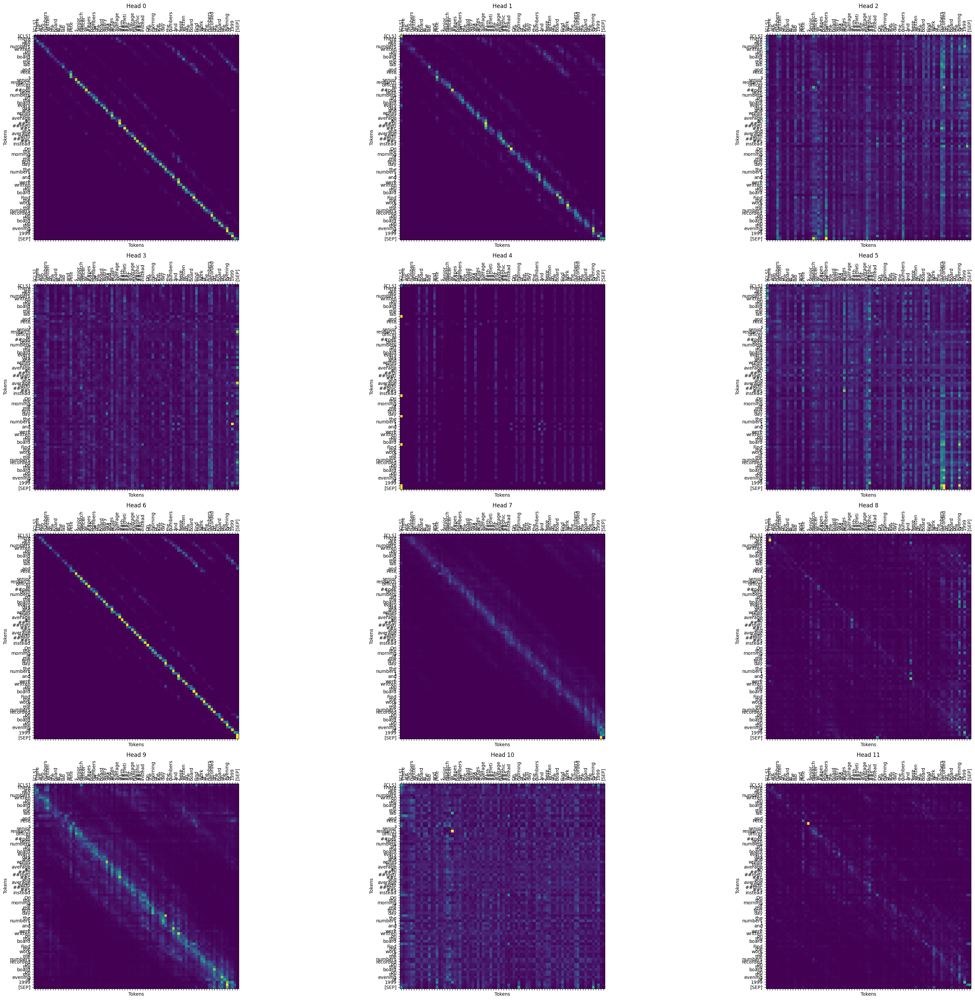

In [52]:
for text in texts_to_analyze:
    print(text)
    draw_first_layer_attention_maps(list(range(best_rubert_freeze.backbone.config.num_attention_heads)), text, best_rubert_freeze, tokenizer_rubert)

Для данной модели - обычная модель с замороженными градиентами - практически нет изменений, то есть модель также улавливает грамматические конструкции и некоторые конструкции, характерные для математических задач.

Delete in a row the numbers 1 to 9 (each time) so that every two consecutively protruding numbers would give a two-digit number divided by 7 or 13.


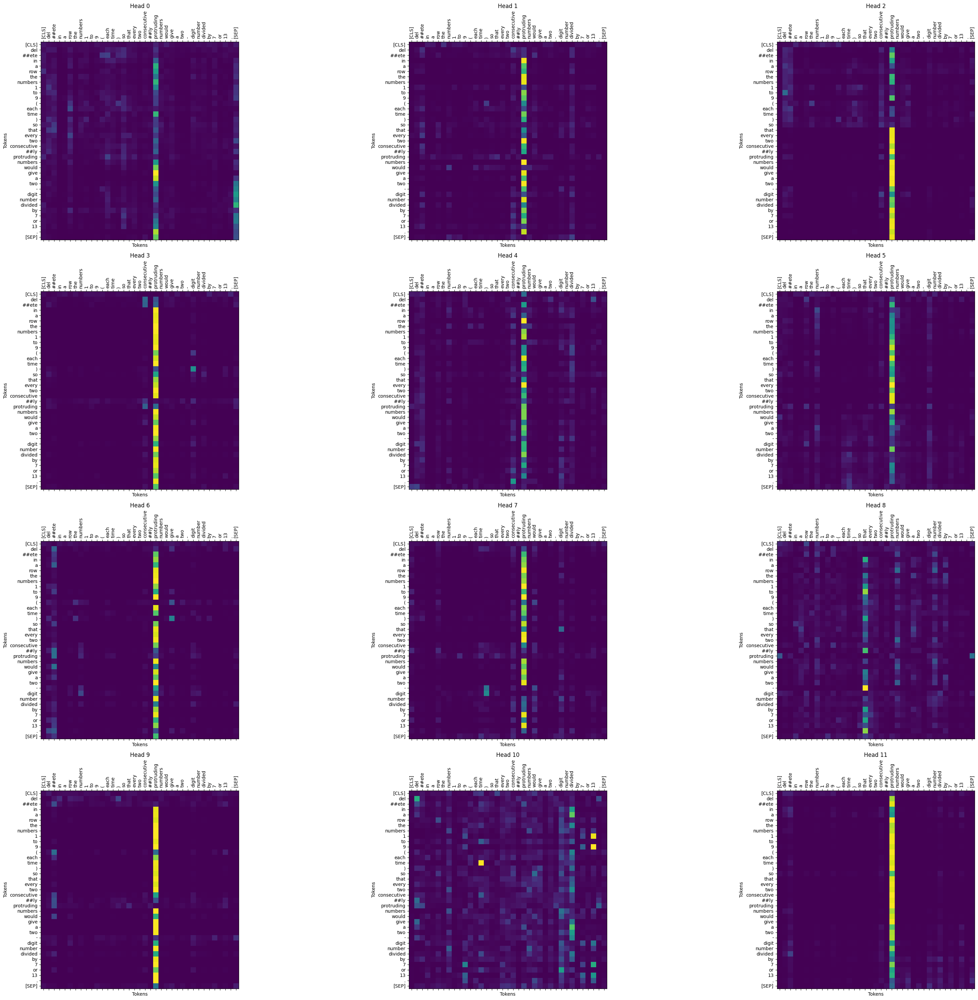

Find the smallest number, which only consists of zeros and units divided by 225.


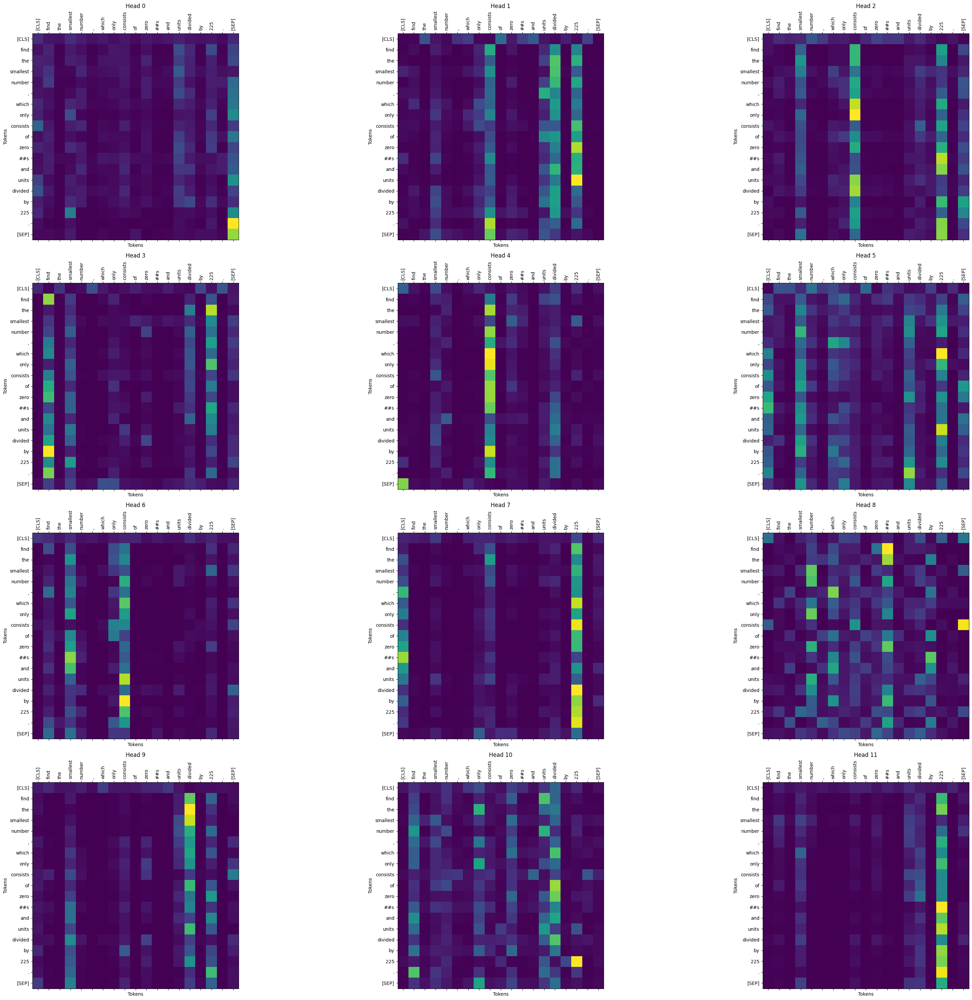

There are two numbers written on the board in the lab, and Pete's senior research officer wipes both numbers off the board every day and writes their average arithmetic and average harmonics instead. On the morning of the first day, the numbers 1 and 2 were written on the board. Find the work of the numbers recorded on the board on the evening of 1999.


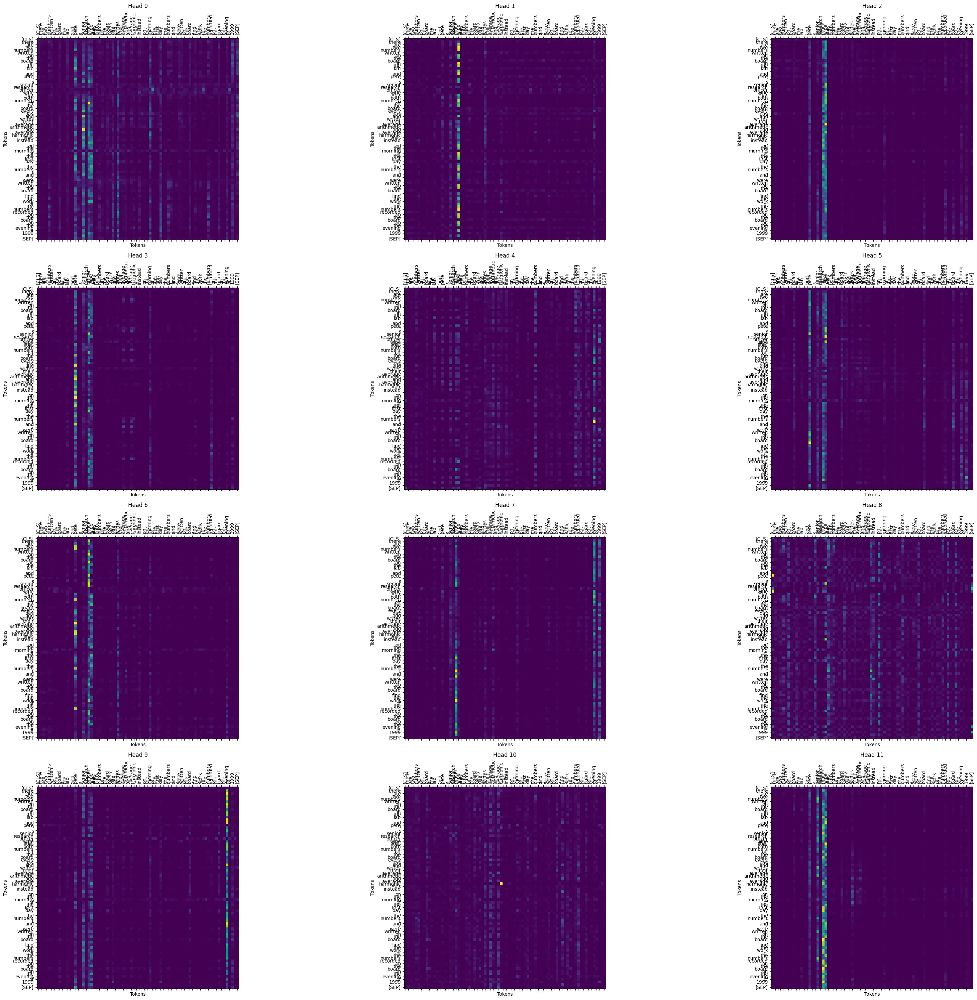

In [53]:
for text in texts_to_analyze:
    print(text)
    draw_first_layer_attention_maps(list(range(best_mathbert_finetune.backbone.config.num_attention_heads)), text, best_mathbert_finetune, tokenizer_mathbert)

Delete in a row the numbers 1 to 9 (each time) so that every two consecutively protruding numbers would give a two-digit number divided by 7 or 13.


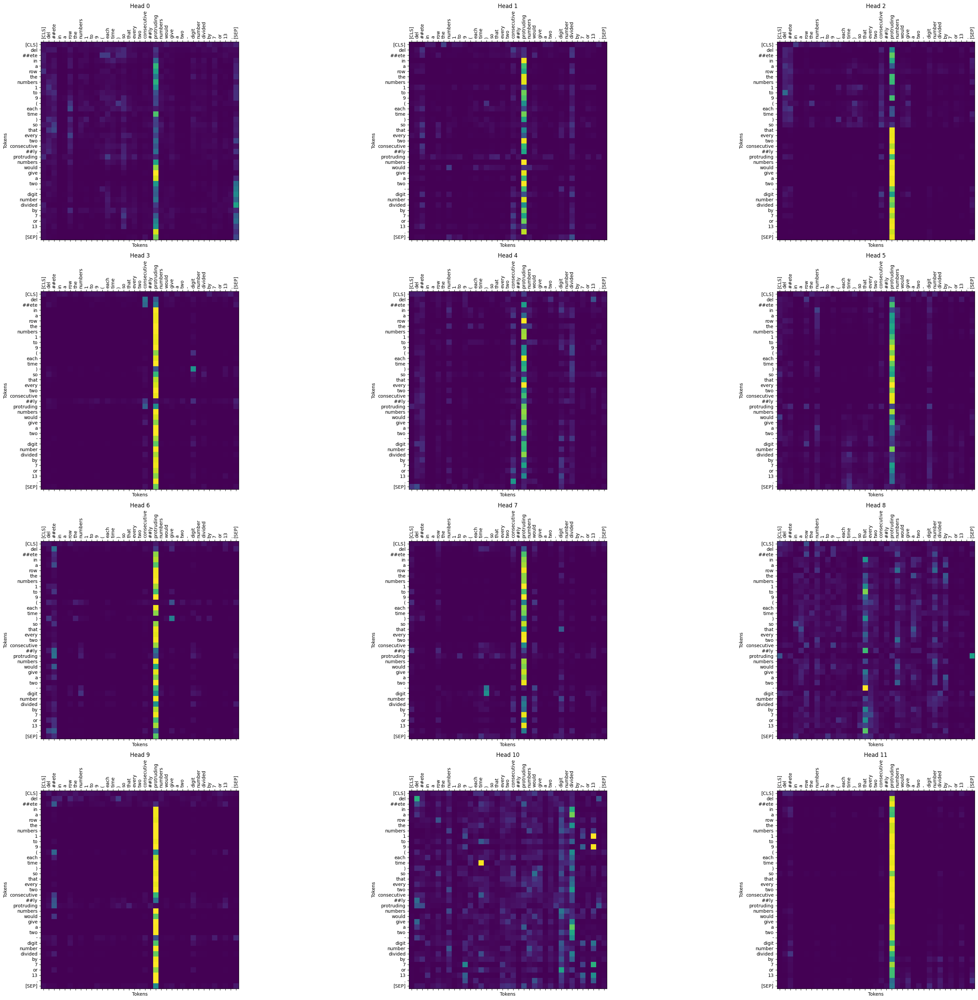

Find the smallest number, which only consists of zeros and units divided by 225.


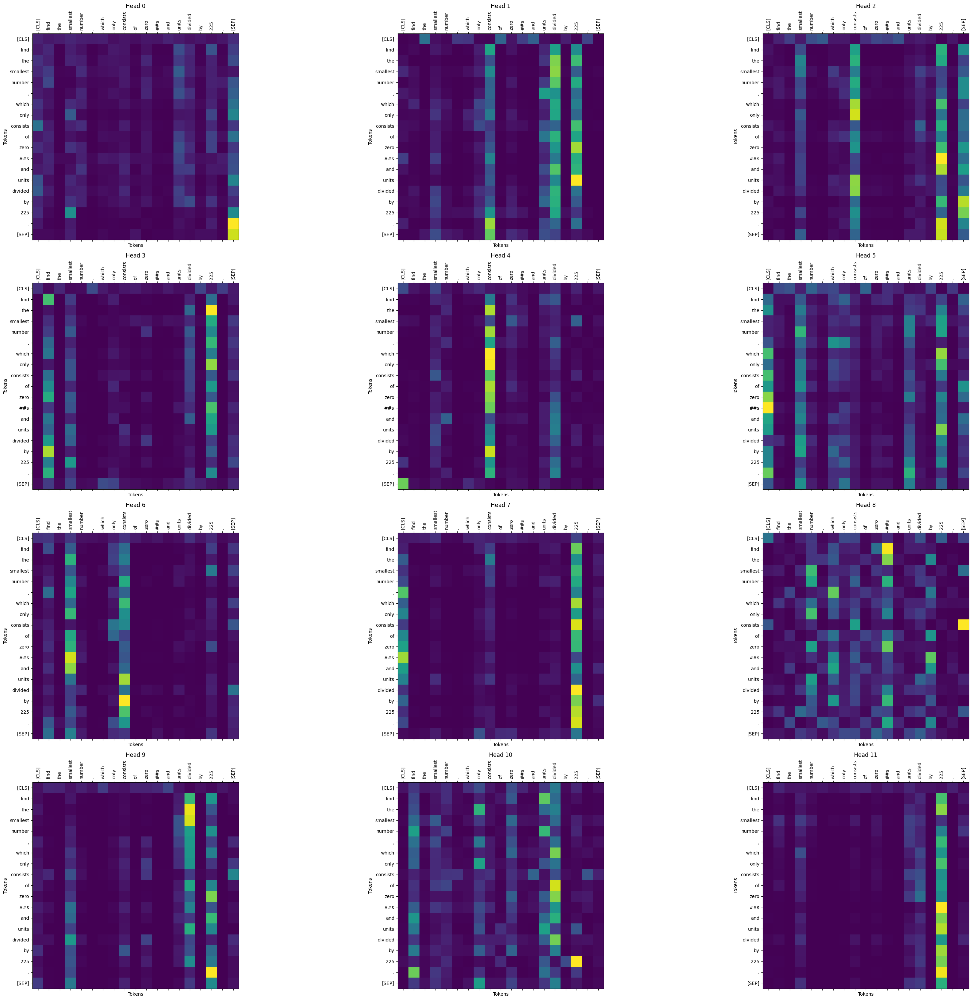

There are two numbers written on the board in the lab, and Pete's senior research officer wipes both numbers off the board every day and writes their average arithmetic and average harmonics instead. On the morning of the first day, the numbers 1 and 2 were written on the board. Find the work of the numbers recorded on the board on the evening of 1999.


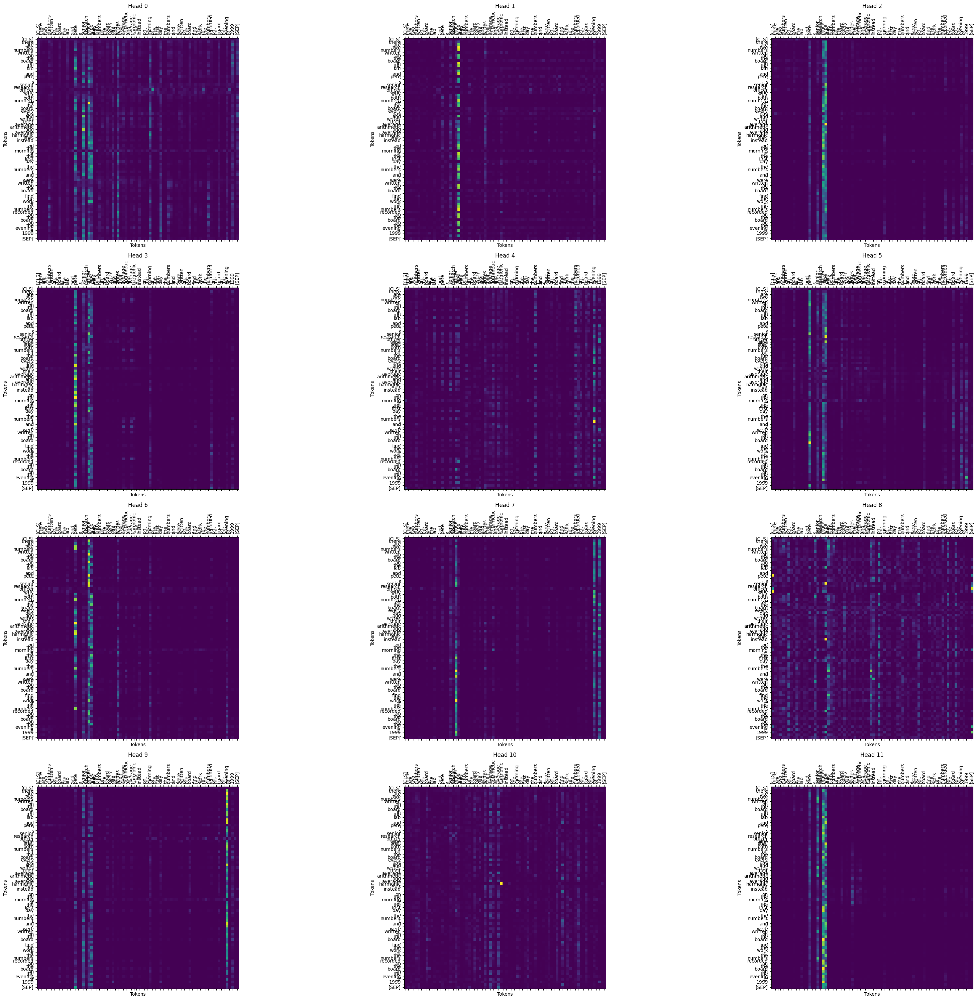

In [54]:
for text in texts_to_analyze:
    print(text)
    draw_first_layer_attention_maps(list(range(best_mathbert_freeze.backbone.config.num_attention_heads)), text, best_mathbert_freeze, tokenizer_mathbert)

Для моделей, которые были дообучены на MathBert, всё также сохраняется внимание на словах, которые характерны для математических задач, но и уже видно внимание на связках слов, которые характеризуют конкретную задачу